In [2]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd

DESCRIPTION_CSV = "wfo_descriptions_with_headers.csv"
TAXONOMY_CSV = "plants_with_taxonomy.csv"

description_df = pd.read_csv(DESCRIPTION_CSV)
taxonomy_df = pd.read_csv(TAXONOMY_CSV)

In [4]:
taxonomy_df[['taxon_name', 'ipni_id', 'phylum', 'class', 'order', 'family']].head()

,taxon_name,ipni_id,phylum,class,order,family
0,Abies numidica,261601-1,Tracheophyta,Pinopsida,Pinales,Pinaceae
1,Abrahamia buxifolia,77175637-1,Tracheophyta,Magnoliopsida,Sapindales,Anacardiaceae
2,Abrahamia deflexa,77175641-1,Tracheophyta,Magnoliopsida,Sapindales,Anacardiaceae
3,Abrahamia ditimena,77175646-1,Tracheophyta,Magnoliopsida,Sapindales,Anacardiaceae
4,Abrahamia ellipticarpa,77175648-1,Tracheophyta,Magnoliopsida,Sapindales,Anacardiaceae


In [5]:
description_df[description_df['description'].notnull()].head()

,ipni_id,description_id,description,provider,citation_ids,citations,url,description_header
19,558106-1,0.0,"Seeds c. 2·5 mm. long, punctate-verruculose. L...",Provided by: [ B ]. Flora Zambesiaca - descrip...,citation1,"1 Malvaceae, A. W. Exell. Flora Zambesiaca 1:2...",https://www.worldfloraonline.org/ipni/558106-1,Morphology
20,558106-1,1.0,"Small shrub, 0.50-0.75 m high. Indumentum of b...",Provided by: [ A ]. e-Flora of South Africa,citation4,"4 Herman, PPJ; Retief, E. 1997. Plants of the ...",https://www.worldfloraonline.org/ipni/558106-1,Morphology
21,558106-1,2.0,"Open vegetation on sandy to gravelly, often br...",Provided by: [ A ]. e-Flora of South Africa,citation4,"4 Herman, PPJ; Retief, E. 1997. Plants of the ...",https://www.worldfloraonline.org/ipni/558106-1,Habitat
23,558442-1,0.0,"Soft shrub (annual?), 0.2-1.5 m high; scantily...",Provided by: [ A ]. e-Flora of South Africa,citation3,"3 Bredenkamp, CL. 2019. Malvaceae s.l. In: CL ...",https://www.worldfloraonline.org/ipni/558442-1,Morphology
24,558442-1,1.0,Rocky slopes in areas with low annual rainfall...,Provided by: [ A ]. e-Flora of South Africa,citation5,"5 Herman, PPJ; Retief, E. 1997. Plants of the ...",https://www.worldfloraonline.org/ipni/558442-1,Habitat


In [6]:
valid_types = ["Morphology", "General Information", "Diagnostic Description", "Habit"]

filtered = description_df[
    description_df["description_header"].isin(valid_types)
].copy()

filtered["has_description"] = filtered["description"].notna()

has_desc = (
    filtered.groupby("ipni_id", as_index=False)["has_description"]
    .max()
)

result_df = taxonomy_df.merge(
    has_desc,
    on="ipni_id",
    how="left"
)

result_df["has_description"] = result_df["has_description"].fillna(False)

result_df.head()

,taxon_name,taxon_authors,plant_name_id_wcvp,ipni_id,kingdom,phylum,class,order,family,has_description
0,Abies numidica,de Lannoy ex Carrière,381929,261601-1,Plantae,Tracheophyta,Pinopsida,Pinales,Pinaceae,False
1,Abrahamia buxifolia,(H.Perrier) Randrian. & Lowry,3226802,77175637-1,Plantae,Tracheophyta,Magnoliopsida,Sapindales,Anacardiaceae,False
2,Abrahamia deflexa,(H.Perrier) Randrian. & Lowry,3226799,77175641-1,Plantae,Tracheophyta,Magnoliopsida,Sapindales,Anacardiaceae,False
3,Abrahamia ditimena,(H.Perrier) Randrian. & Lowry,3226767,77175646-1,Plantae,Tracheophyta,Magnoliopsida,Sapindales,Anacardiaceae,False
4,Abrahamia ellipticarpa,Randrian. & Lowry,3226780,77175648-1,Plantae,Tracheophyta,Magnoliopsida,Sapindales,Anacardiaceae,False


In [7]:
summary = (
    result_df["has_description"]
    .value_counts(dropna=False)
    .rename_axis("has_description")
    .reset_index(name="count")
)

summary["percent"] = 100 * summary["count"] / summary["count"].sum()

print("\nOverall Summary:")
print(summary)


Overall Summary:
   has_description  count    percent
0            False   6034  51.178965
1             True   5756  48.821035


In [19]:
import matplotlib.pyplot as plt

def plot_top_groups(summary_df, rank_col, title, n=20):
    top = (
        summary_df
        .sort_values("total", ascending=False)
        .head(n)
        .sort_values("percent_with_description")
    )

    plt.figure(figsize=(10, 6))

    plt.barh(
        top[rank_col],
        top["percent_with_description"]
    )

    plt.xlabel("% with description")
    plt.ylabel(rank_col.capitalize())
    plt.title(title) 

    plt.tight_layout()
    plt.show()

In [18]:
def summarize_by_rank(df, rank):
    summary = (
        df.groupby(rank)
        .agg(
            total=("has_description", "size"),
            with_description=("has_description", lambda x: int(sum(x)))
        )
        .reset_index()
    )

    summary["without_description"] = (
        summary["total"] - summary["with_description"]
    )

    summary["percent_with_description"] = (
        100 * summary["with_description"] / summary["total"]
    )

    return summary.sort_values(
        "with_description",
        ascending=False
    )

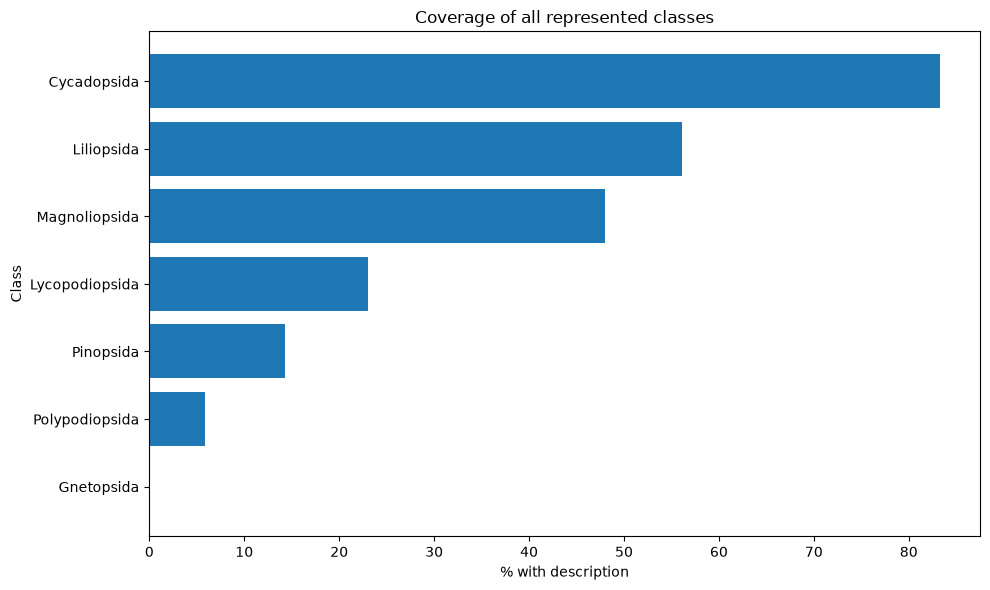

In [20]:
class_summary  = summarize_by_rank(result_df, "class")

plot_top_groups(class_summary, "class", f"Coverage of all represented classes", len(class_summary))

In [11]:
print("\nClass Summary:")
print(class_summary)


Class Summary:
            class  total  with_description  without_description  \
4   Magnoliopsida   9306              4471                 4835   
2      Liliopsida   2223              1248                  975   
0     Cycadopsida     18                15                    3   
6  Polypodiopsida    204                12                  192   
3  Lycopodiopsida     26                 6                   20   
5       Pinopsida      7                 1                    6   
1      Gnetopsida      2                 0                    2   

   percent_with_description  
4                 48.044273  
2                 56.140351  
0                 83.333333  
6                  5.882353  
3                 23.076923  
5                 14.285714  
1                  0.000000  


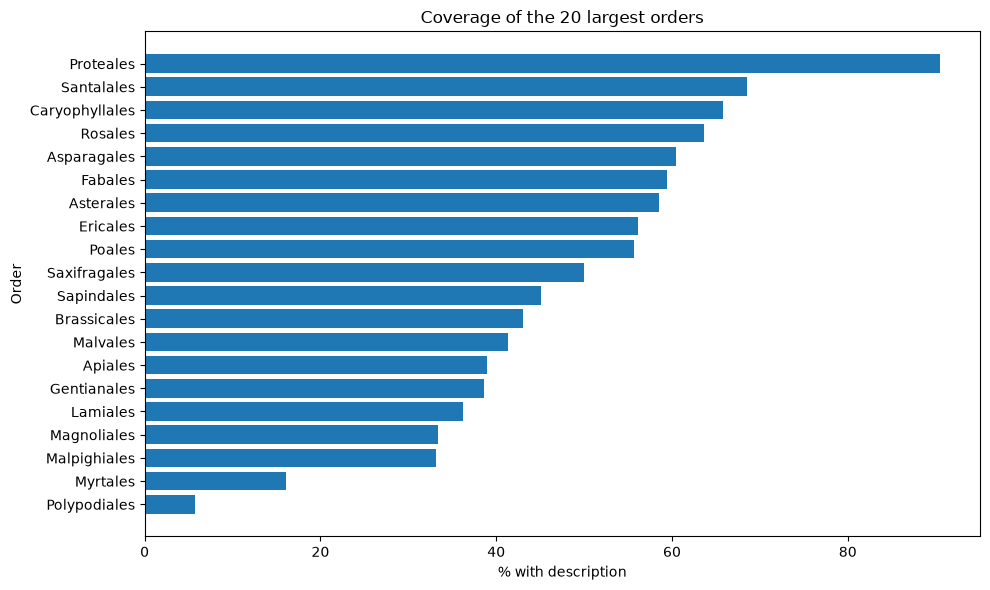

In [22]:
order_summary  = summarize_by_rank(result_df, "order")

plot_top_groups(order_summary, "order", "Coverage of the 20 largest orders")

In [13]:
print("\nOrder Summary:")

pd.Series({
    "n_orders": len(order_summary),
    "orders_with_any_descriptions":
        (order_summary["with_description"] > 0).sum(),
    "orders_with_no_descriptions":
        (order_summary["with_description"] == 0).sum(),
    "mean_order_coverage":
        order_summary["percent_with_description"].mean(),
    "median_order_coverage":
        order_summary["percent_with_description"].median(),
})


Order Summary:


n_orders                        65.000000
orders_with_any_descriptions    56.000000
orders_with_no_descriptions      9.000000
mean_order_coverage             40.460348
median_order_coverage           40.000000
dtype: float64

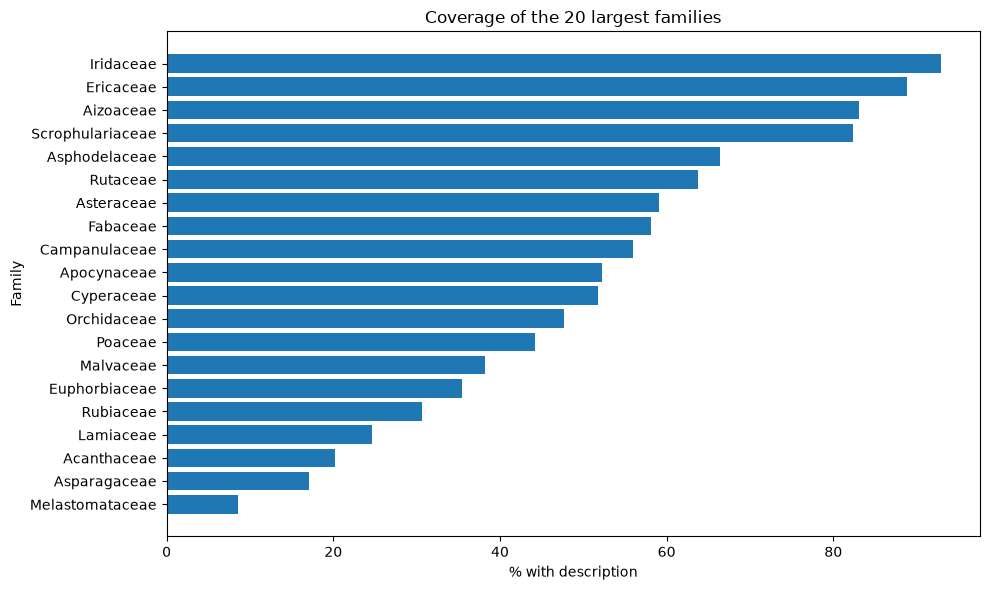

In [21]:
family_summary = summarize_by_rank(result_df, "family")

plot_top_groups(family_summary, "family", "Coverage of the 20 largest families")

In [15]:
print("\nFamily Summary:")

pd.Series({
    "n_families": len(family_summary),
    "families_with_any_descriptions":
        (family_summary["with_description"] > 0).sum(),
    "families_with_no_descriptions":
        (family_summary["with_description"] == 0).sum(),
    "mean_family_coverage":
        family_summary["percent_with_description"].mean(),
    "median_family_coverage":
        family_summary["percent_with_description"].median()
})


Family Summary:


n_families                        250.000000
families_with_any_descriptions    192.000000
families_with_no_descriptions      58.000000
mean_family_coverage               40.563099
median_family_coverage             35.358658
dtype: float64